In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras

from fftdeep.data.arrays import get_arrays
from fftdeep.evaluation.metrics import binary_metrics, plot_roc
from fftdeep.paths import PROJECT_ROOT

Xva, yva = get_arrays("val")
Xva = Xva.astype("float32")

variants = ["baseline", "deeper"]
probs = {}
for v in variants:
    model = keras.models.load_model(PROJECT_ROOT / "models" / f"cnn_{v}.keras", compile=False)
    probs[v] = model.predict(Xva, batch_size=512, verbose=0).ravel()

table = pd.DataFrame({v: binary_metrics(yva, probs[v]) for v in variants}).T
print(table[["accuracy", "precision", "recall", "specificity", "f1", "roc_auc"]].round(4))

          accuracy  precision  recall  specificity      f1  roc_auc
baseline    0.9474     0.9422  0.9519       0.9431  0.9470   0.9881
deeper      0.9514     0.9563  0.9448       0.9579  0.9505   0.9902


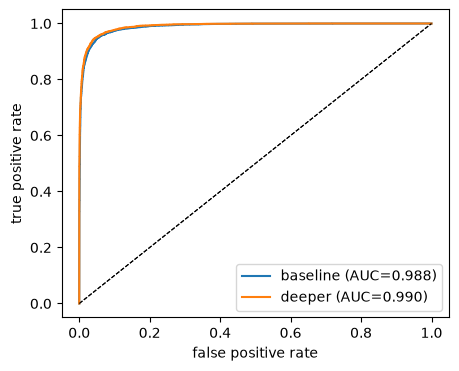

In [2]:
fig, ax = plt.subplots(figsize=(5, 4))
for v in variants:
    plot_roc(yva, probs[v], v, ax)
plt.show()

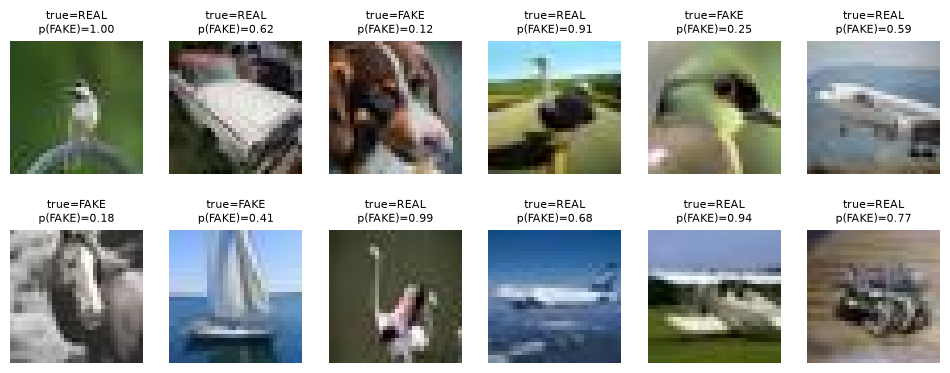

In [3]:
wrong = np.where((probs["baseline"] >= 0.5).astype(int) != yva)[0]
pick = np.random.default_rng(0).choice(wrong, 12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, i in zip(axes.ravel(), pick):
    ax.imshow(Xva[i].astype("uint8"))
    ax.set_title(f"true={'FAKE' if yva[i] else 'REAL'}\np(FAKE)={probs['baseline'][i]:.2f}", fontsize=8)
    ax.axis("off")
plt.show()

12 epochs ran


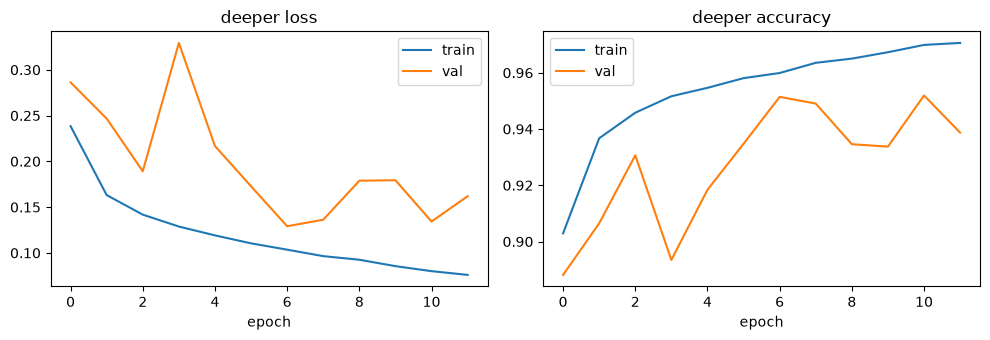

In [4]:
#  loss and accuracy for training and validation dataset for Model B ( deeper ) 
import json
from fftdeep.evaluation.metrics import plot_history

hist_b = json.loads((PROJECT_ROOT / "reports" / "history_deeper.json").read_text())
print(len(hist_b["loss"]), "epochs ran")
plot_history(hist_b, "deeper")
plt.show()


In [5]:
from scipy.stats import binomtest

pa = (probs["baseline"] >= 0.5).astype(int)
pb = (probs["deeper"] >= 0.5).astype(int)
a_ok, b_ok = pa == yva, pb == yva
only_a = int((a_ok & ~b_ok).sum())    # A right, B wrong
only_b = int((~a_ok & b_ok).sum())    # B right, A wrong
print(only_a, only_b, binomtest(only_b, only_a + only_b, 0.5).pvalue)

386 465 0.007463561256022334
